# Evaluating out-of-distribution detector

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [2]:
NUM_SAMPLES = 25
SAMPLE_SIZE = 500
SEED = 123

In [3]:
sequences = pd.read_csv('../data/interim/sequences_sample_1500_af_training.csv', index_col='id')
sequences['fold'] = sequences['fold'].astype(str)
sequences['type'] = sequences['label'].map(lambda label: 'Binding' if label else 'Non-Binding')
sequences['source_label'] = sequences['source'].map(lambda source: int(source == 'Sequences'))

In [4]:
pca = pd.read_csv('../data/interim/af3_af3_tcrmodel2_cropped_pae_pca_training.csv')
pca = pca.merge(sequences, how='left', left_on='name', right_index=True)

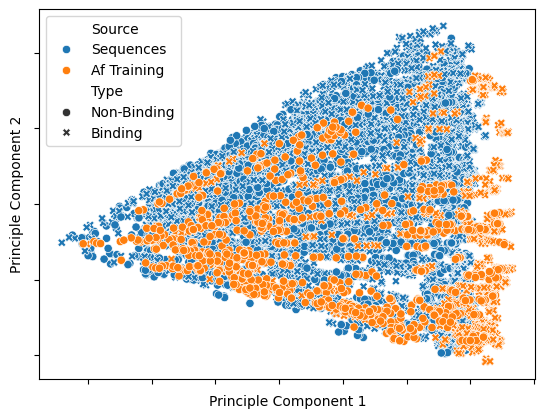

In [5]:
ax = sns.scatterplot(pca, x='pc1', y='pc2', hue='source', style='type')

ax.set_xticklabels([])
ax.set_yticklabels([])

ax.set_xlabel('Principle Component 1')
ax.set_ylabel('Principle Component 2')

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles, labels=[label.title() for label in labels])

plt.savefig('../report/figures/PAE_PCA.svg')
plt.show()